# H4a Polaryzacja afektywna (WPA)

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from src.config import (APA_STYLE, CYCLES, EDA_STYLE, GROUP_COLORS, GROUP_LABELS, GROUP_LINESTYLES, PEAK_COLOR, PHASE_COLORS,
                        PHASE_LABELS, PHASE_ORDER, POLITICAL_SUBREDDITS, PROCESSED_DIR, RESULTS_DIR, SUBREDDITS, WPA_MIN_PER_GROUP)

plt.rcParams.update(APA_STYLE)
plt.rcParams.update(EDA_STYLE)

H4A_DIR = PROCESSED_DIR / "h4a"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CELLS = ["subreddit", "cycle", "phase"]

PHASE_TICKS = [PHASE_LABELS[phase] for phase in PHASE_ORDER]
SUBREDDIT_PANELS = [[subreddit] for subreddit in POLITICAL_SUBREDDITS]
CAMP_PANELS = [["dem"], ["rep"]]
JOINT_PANEL = [["dem", "rep"]]
SCOPE_STYLES = {"all": ("#eb6834", "o", "Wszystkie terminy"), "party": ("#6250d6", "s", "Partie i zwolennicy"),
                "politician": ("#1baf7a", "^", "Politycy")}
VARIANT_STYLES = {"wpa": ("-", "2 klasy NLI"), "wpa_3class": ("--", "3 klasy NLI")}

In [2]:
def group_handles(groups):
    return [Line2D([], [], color=GROUP_COLORS[group], linestyle=GROUP_LINESTYLES[group], linewidth=1.6, marker="o", markersize=4,
                   label=GROUP_LABELS[group]) for group in groups]


def group_series(group, **conditions):
    rows = wpa_groups[wpa_groups["group"] == group]
    for column, value in conditions.items():
        rows = rows[rows[column] == value]
    return rows


def finish_figure(fig, handles, title, xlabel, ylabel, top=0.9, legend_y=0.965):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, legend_y), ncol=4)
    fig.supxlabel(xlabel)
    fig.supylabel(ylabel)
    plt.tight_layout(rect=(0.02, 0, 0.99, top))
    plt.show()


def plot_wpa_phases(panels, title):
    """Siatka: wiersz = cykl, kolumna = panel; oś X = fazy cyklu, linia = subreddit lub obóz."""
    fig, axes = plt.subplots(len(CYCLES), len(panels), figsize=(max(9, 3.6 * len(panels)), 9.5), sharex=True, sharey=True, squeeze=False)
    for row, cycle in enumerate(CYCLES):
        for column, groups in enumerate(panels):
            ax = axes[row, column]
            ax.axvspan(PHASE_ORDER.index("szczytowa") - 0.5, PHASE_ORDER.index("szczytowa") + 0.5, color=PEAK_COLOR, linewidth=0)
            ax.axhline(0, color="0.5", linewidth=0.8, linestyle="--")
            for group in groups:
                rows = group_series(group, cycle=cycle).set_index("phase").reindex(PHASE_ORDER)
                ax.plot(range(len(PHASE_ORDER)), rows["wpa"], color=GROUP_COLORS[group], linestyle=GROUP_LINESTYLES[group],
                        marker="o", markersize=4, linewidth=1.6)
            ax.set_title(f"{' i '.join(GROUP_LABELS[group] for group in groups)} · cykl {cycle}", loc="left", fontsize=9)
            ax.set_xticks(range(len(PHASE_ORDER)), PHASE_TICKS, rotation=30, ha="right", fontsize=8)
    handles = group_handles(panels[0]) if len(panels[0]) > 1 else []
    handles += [Patch(color=PEAK_COLOR, label="Faza szczytowa"), Line2D([], [], color="0.5", linewidth=0.8, linestyle="--", label="WPA = 0")]
    finish_figure(fig, handles, title, "Faza cyklu", "WPA (krytyka obozu przeciwnego − własnego)")


def plot_wpa_cycles(groups, title):
    """Dwa panele (faza szczytowa i przejściowa); oś X = cykl, linia = subreddit lub obóz."""
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), sharey=True)
    for ax, phase in zip(axes, ["szczytowa", "przejsciowa"]):
        ax.axhline(0, color="0.5", linewidth=0.8, linestyle="--")
        for group in groups:
            rows = group_series(group, phase=phase).set_index("cycle").reindex(CYCLES)
            ax.plot(CYCLES, rows["wpa"], color=GROUP_COLORS[group], linestyle=GROUP_LINESTYLES[group], marker="o", markersize=4,
                    linewidth=1.6)
        ax.set_title(f"Faza {PHASE_LABELS[phase].lower()}", loc="left", fontsize=9)
        ax.set_xticks(CYCLES)
    handles = group_handles(groups) + [Line2D([], [], color="0.5", linewidth=0.8, linestyle="--", label="WPA = 0")]
    finish_figure(fig, handles, title, "Cykl wyborczy", "WPA (krytyka obozu przeciwnego − własnego)", top=0.74, legend_y=0.91)

## 2. Połączenie wzmianek z wynikami modelu

In [3]:
mentions = pd.read_parquet(H4A_DIR / "mentions.parquet", columns=["id", "subreddit", "cycle", "phase", "target", "term_type"])
stance = pd.concat(pd.read_parquet(path) for path in sorted(H4A_DIR.glob("stance_*.parquet")))
data = mentions.merge(stance, on="id")
print(len(mentions), len(data))

95312 95312


## 3. WPA = odsetek krytyki obozu przeciwnego − własnego

In [4]:
variants = {"wpa": "critical", "wpa_3class": "critical_3"}
scopes = {"all": data, "party": data[data["term_type"] == "party"], "politician": data[data["term_type"] == "politician"]}
tables = []
for scope, subset in scopes.items():
    for variant, column in variants.items():
        rate = subset.pivot_table(index=CELLS, columns="target", values=column, aggfunc="mean").reindex(columns=["out", "own"])
        count = subset.pivot_table(index=CELLS, columns="target", values=column, aggfunc="size").reindex(columns=["out", "own"])
        table = pd.DataFrame({"n_out": count["out"], "n_own": count["own"], "wpa": rate["out"] - rate["own"]})
        table.loc[(table["n_out"] < WPA_MIN_PER_GROUP) | (table["n_own"] < WPA_MIN_PER_GROUP), "wpa"] = float("nan")
        tables.append(table.assign(scope=scope, variant=variant).reset_index())
wpa = pd.concat(tables, ignore_index=True)
wpa.to_csv(RESULTS_DIR / "h4a_wpa.csv", index=False)
main = wpa[(wpa["scope"] == "all") & (wpa["variant"] == "wpa")]
wpa_table = main.pivot_table(index=["subreddit", "phase"], columns="cycle", values="wpa")
wpa_table.round(3)

cycle                        2012   2016   2020   2024
subreddit    phase                                    
Conservative bazowa        -0.055  0.255  0.285  0.141
             powyborcza     0.157  0.189  0.172  0.087
             przedwyborcza  0.013  0.190  0.276  0.150
             przejsciowa    0.239  0.154  0.062  0.327
             szczytowa      0.082  0.121  0.152  0.347
Liberal      bazowa           NaN  0.328  0.391  0.450
             powyborcza     0.247  0.384  0.492  0.468
             przedwyborcza  0.311  0.274  0.419  0.477
             przejsciowa    0.351  0.278  0.499  0.324
             szczytowa      0.393  0.316  0.503  0.465
Republican   bazowa        -0.190  0.071  0.415  0.170
             powyborcza    -0.075 -0.052  0.209  0.240
             przedwyborcza -0.004 -0.003  0.363  0.245
             przejsciowa   -0.031 -0.029  0.125  0.378
             szczytowa      0.046 -0.103  0.387  0.375
democrats    bazowa           NaN  0.351  0.507  0.585
             powyborcza     0.357  0.329  0.524  0.407
             przedwyborcza  0.420  0.331  0.507  0.553
             przejsciowa    0.448  0.369  0.496  0.486
             szczytowa      0.382  0.413  0.553  0.574

In [5]:
by_subreddit = main[["subreddit", "cycle", "phase", "wpa"]].rename(columns={"subreddit": "group"})
by_camp = (main.assign(group=main["subreddit"].map(SUBREDDITS)).groupby(["group", "cycle", "phase"], as_index=False)["wpa"]
           .agg(lambda values: values.mean(skipna=False)))
wpa_groups = pd.concat([by_subreddit, by_camp], ignore_index=True)
wpa_groups.groupby("group")["wpa"].agg(["mean", "count"]).round(3)

,mean,count
group,,
Conservative,0.167,20
Liberal,0.388,19
Republican,0.127,20
dem,0.420,19
democrats,0.452,19
rep,0.147,20


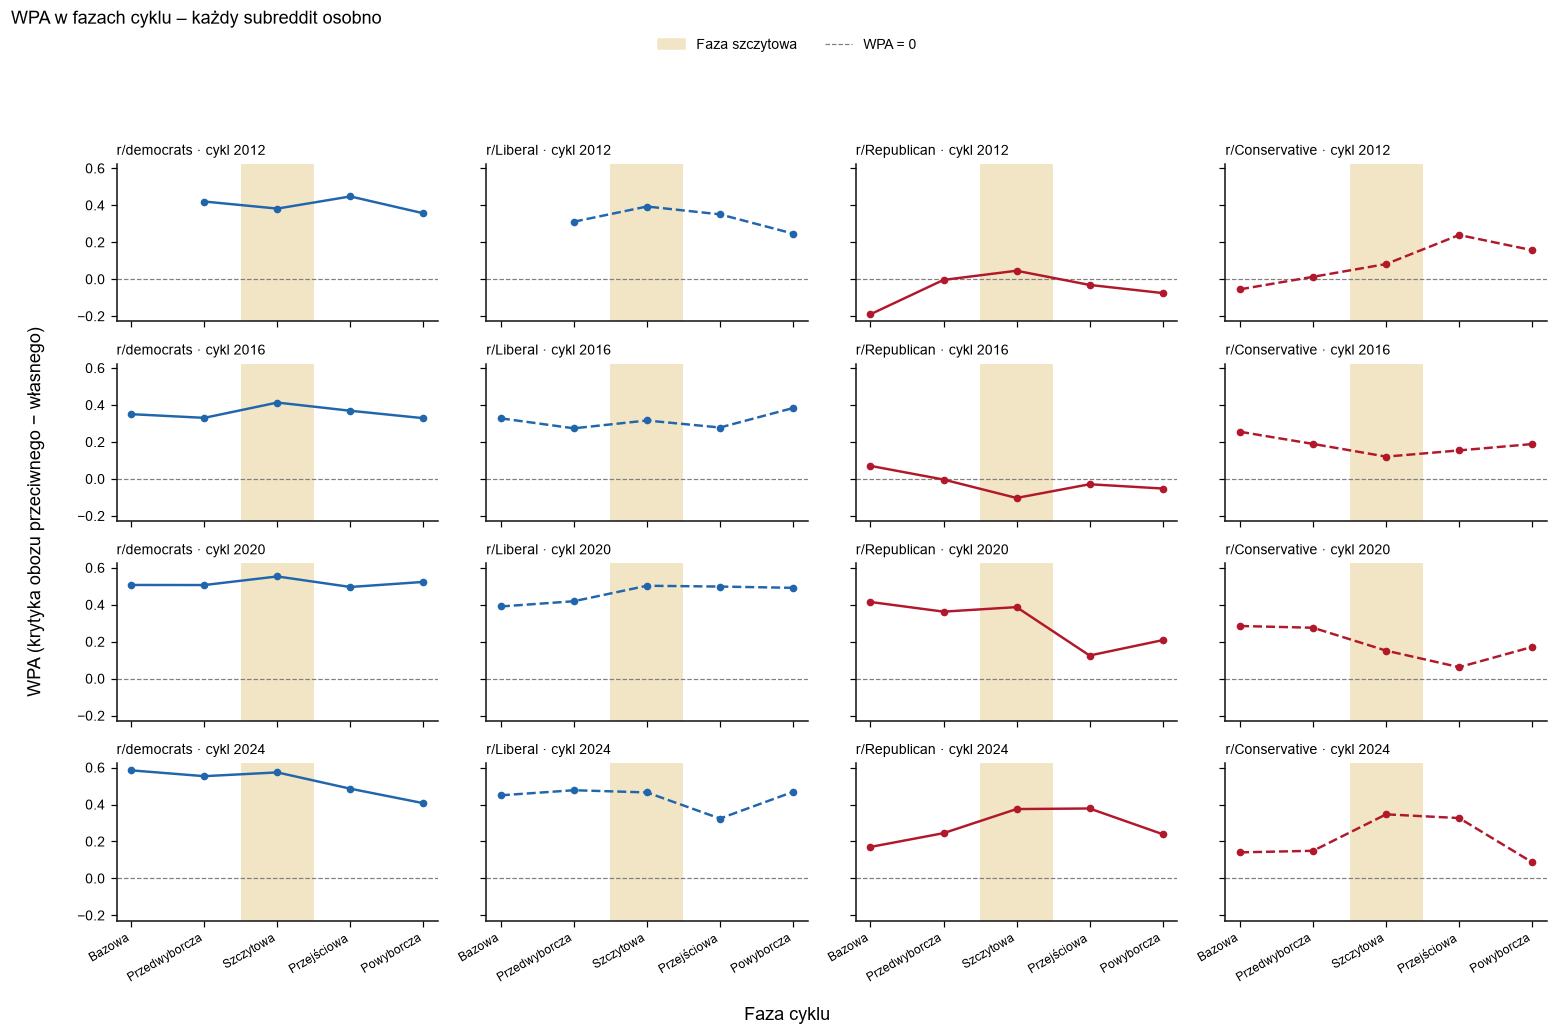

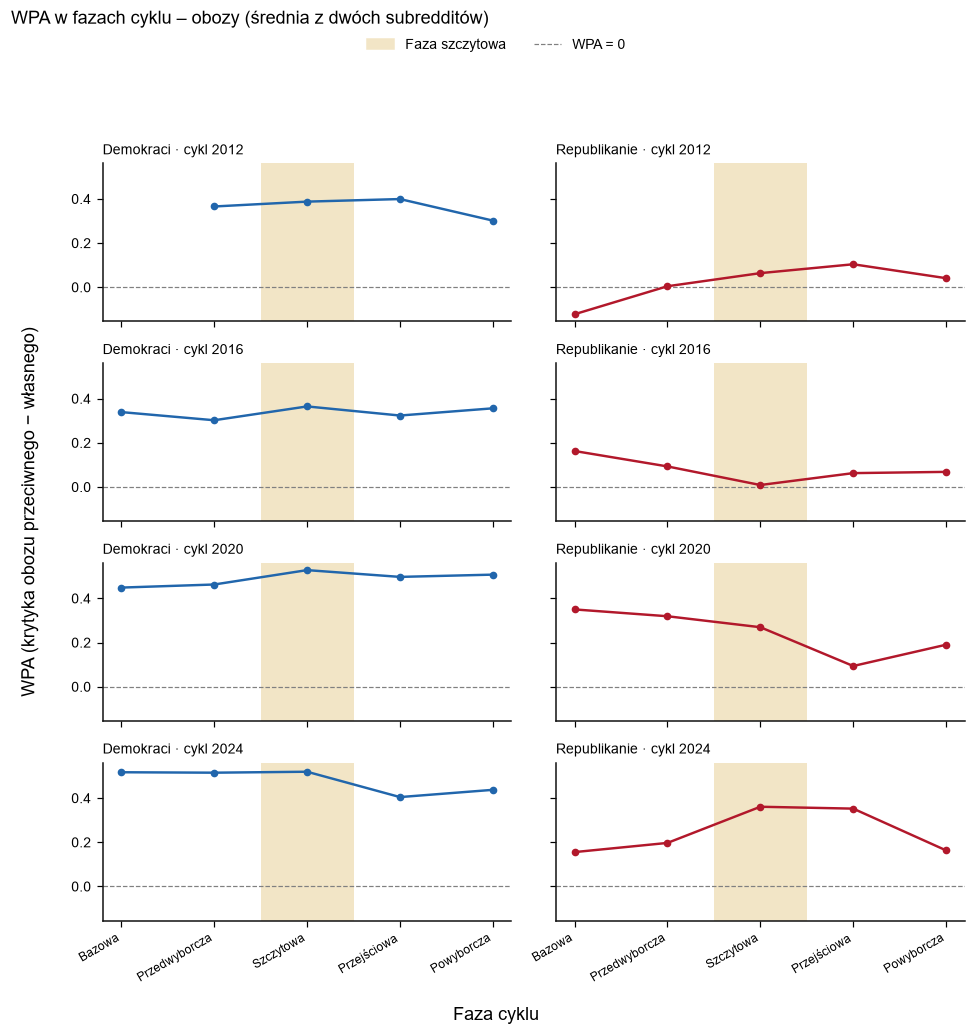

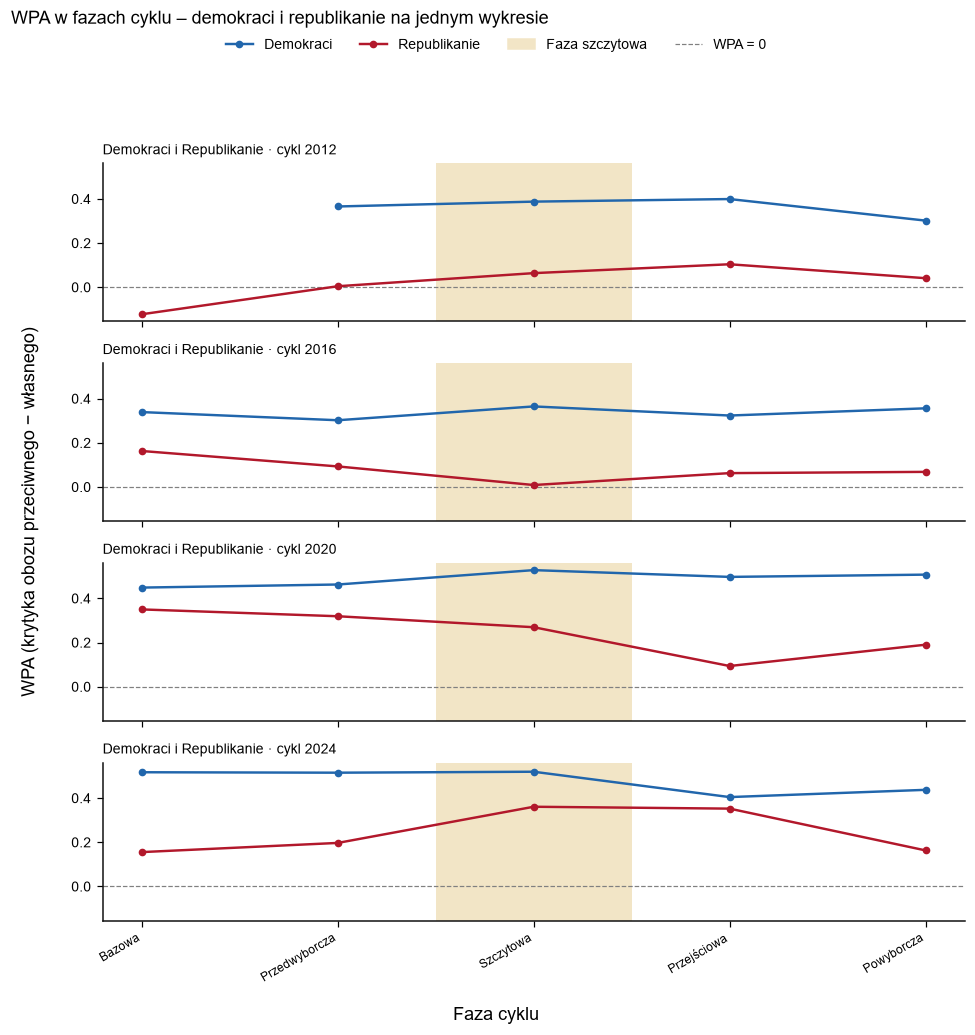

In [6]:
plot_wpa_phases(SUBREDDIT_PANELS, "WPA w fazach cyklu – każdy subreddit osobno")
plot_wpa_phases(CAMP_PANELS, "WPA w fazach cyklu – obozy (średnia z dwóch subredditów)")
plot_wpa_phases(JOINT_PANEL, "WPA w fazach cyklu – demokraci i republikanie na jednym wykresie")

In [7]:
print("komórki bez WPA (za mało komentarzy w koszyku):")
main[main["wpa"].isna()][CELLS + ["n_out", "n_own"]]

komórki bez WPA (za mało komentarzy w koszyku):


,subreddit,cycle,phase,n_out,n_own
20,Liberal,2012,bazowa,21,38
60,democrats,2012,bazowa,48,38


## 4. Porównanie: 2020 + 2024 vs 2012 + 2016

In [8]:
main = main.assign(period=main["cycle"].map(lambda cycle: "2020+2024" if cycle >= 2020 else "2012+2016"))
comparison = main[main["phase"].isin(["szczytowa", "przejsciowa"])].groupby(["phase", "period"])["wpa"].agg(mean="mean", n_cells="count")
comparison.to_csv(RESULTS_DIR / "h4a_period_comparison.csv")
comparison.round(3)

mean  n_cells
phase       period                   
przejsciowa 2012+2016  0.223        8
            2020+2024  0.337        8
szczytowa   2012+2016  0.206        8
            2020+2024  0.420        8

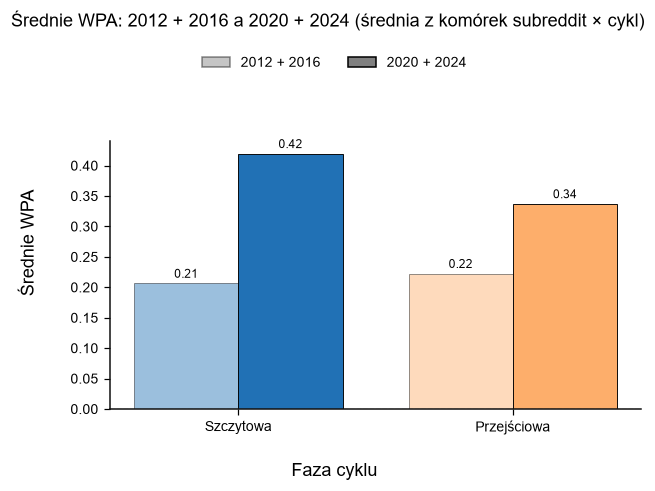

In [9]:
period_means = comparison["mean"].unstack("period").loc[["szczytowa", "przejsciowa"], ["2012+2016", "2020+2024"]]
fig, ax = plt.subplots(figsize=(6, 4.4))
positions = np.arange(len(period_means))
width = 0.38
for offset, period, alpha in ((-width / 2, "2012+2016", 0.45), (width / 2, "2020+2024", 1)):
    bars = ax.bar(positions + offset, period_means[period], width, alpha=alpha, edgecolor="black", linewidth=0.6,
                  color=[PHASE_COLORS[phase] for phase in period_means.index])
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.axhline(0, color="0.5", linewidth=0.8, linestyle="--")
ax.set_xticks(positions, [PHASE_LABELS[phase] for phase in period_means.index])
handles = [Patch(facecolor="0.5", edgecolor="black", alpha=0.45, label="2012 + 2016"), Patch(facecolor="0.5", edgecolor="black", label="2020 + 2024")]
finish_figure(fig, handles, "Średnie WPA: 2012 + 2016 a 2020 + 2024 (średnia z komórek subreddit × cykl)", "Faza cyklu", "Średnie WPA", top=0.82, legend_y=0.91)

## 5. Analiza wrażliwości: typ terminu i wariant z trzech klas

In [10]:
sensitivity = wpa[wpa["phase"].isin(["szczytowa", "przejsciowa"])].pivot_table(index=["scope", "variant", "phase"], columns="cycle", values="wpa", aggfunc="mean")
sensitivity.round(3)

cycle                               2012   2016   2020   2024
scope      variant    phase                                  
all        wpa        przejsciowa  0.252  0.193  0.296  0.379
                      szczytowa    0.226  0.187  0.399  0.440
           wpa_3class przejsciowa  0.252  0.192  0.296  0.379
                      szczytowa    0.226  0.187  0.398  0.440
party      wpa        przejsciowa  0.319  0.265  0.328  0.382
                      szczytowa    0.275  0.238  0.409  0.426
           wpa_3class przejsciowa  0.319  0.262  0.328  0.382
                      szczytowa    0.275  0.238  0.409  0.426
politician wpa        przejsciowa -0.006  0.156  0.256  0.368
                      szczytowa    0.194  0.166  0.381  0.431
           wpa_3class przejsciowa -0.006  0.156  0.256  0.368
                      szczytowa    0.194  0.166  0.379  0.431

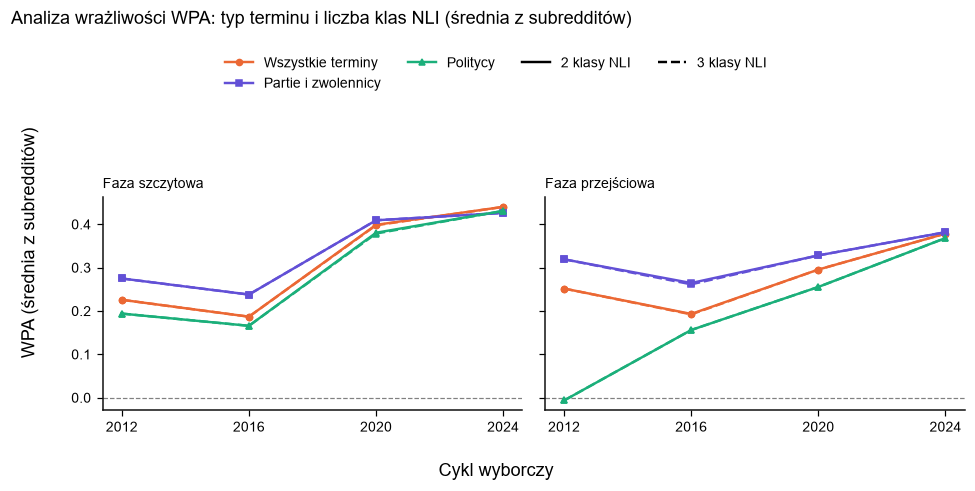

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), sharey=True)
for ax, phase in zip(axes, ["szczytowa", "przejsciowa"]):
    ax.axhline(0, color="0.5", linewidth=0.8, linestyle="--")
    for (scope, variant), row in sensitivity.xs(phase, level="phase").iterrows():
        color, marker, _ = SCOPE_STYLES[scope]
        ax.plot(CYCLES, row.reindex(CYCLES), color=color, marker=marker, markersize=4, linewidth=1.6, linestyle=VARIANT_STYLES[variant][0])
    ax.set_title(f"Faza {PHASE_LABELS[phase].lower()}", loc="left", fontsize=9)
    ax.set_xticks(CYCLES)
handles = [Line2D([], [], color=color, marker=marker, markersize=4, linewidth=1.6, label=label) for color, marker, label in SCOPE_STYLES.values()]
handles += [Line2D([], [], color="black", linestyle=linestyle, linewidth=1.6, label=label) for linestyle, label in VARIANT_STYLES.values()]
finish_figure(fig, handles, "Analiza wrażliwości WPA: typ terminu i liczba klas NLI (średnia z subredditów)", "Cykl wyborczy",
              "WPA (średnia z subredditów)", top=0.74, legend_y=0.91)

## 6. WPA w kolejnych cyklach – fazy szczytowa i przejściowa

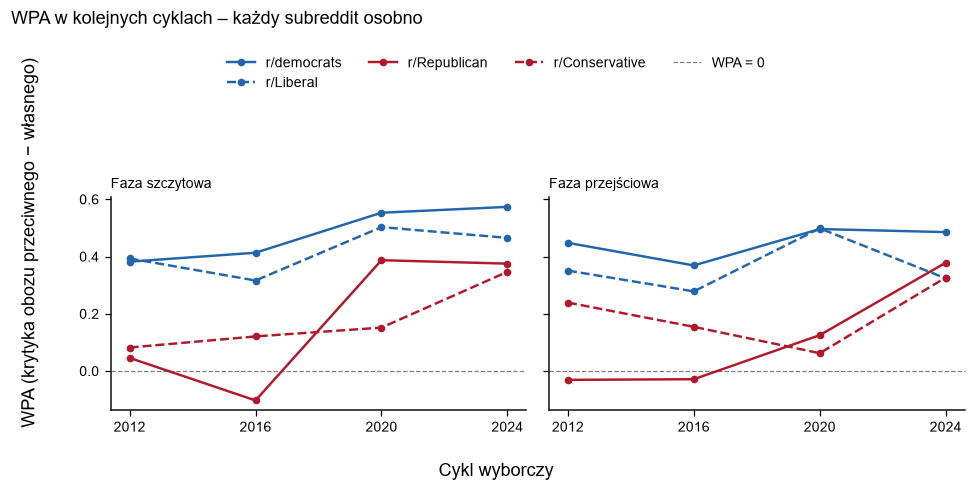

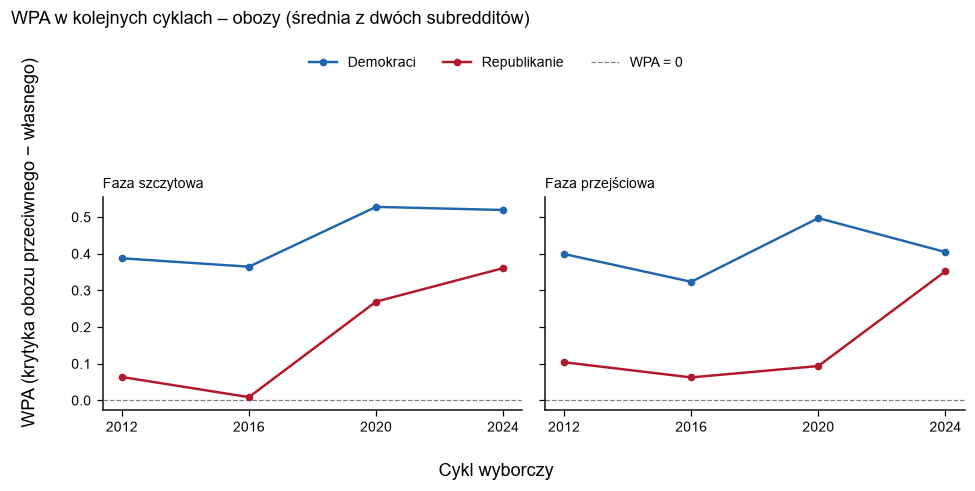

In [12]:
plot_wpa_cycles(POLITICAL_SUBREDDITS, "WPA w kolejnych cyklach – każdy subreddit osobno")
plot_wpa_cycles(["dem", "rep"], "WPA w kolejnych cyklach – obozy (średnia z dwóch subredditów)")